In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/credit_default_clean.csv")

X = df.drop(columns=["DEFAULT", "SEX"])
y = df["DEFAULT"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(21000, 22) (9000, 22)
0.221 0.221


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

# Scale features so the coefficients are comparable
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42),
)
logreg.fit(X_train, y_train)

# Predicted probability of default (PD) on the test set
pd_test = logreg.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, pd_test)
print("AUC:", round(auc, 3))
print("Gini:", round(2 * auc - 1, 3))

AUC: 0.714
Gini: 0.427


In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Gradient boosting handles non-linear effects and needs no scaling
gb = HistGradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)

# Predicted probability of default (PD) on the test set
pd_test_gb = gb.predict_proba(X_test)[:, 1]

auc_gb = roc_auc_score(y_test, pd_test_gb)
print("AUC:", round(auc_gb, 3))
print("Gini:", round(2 * auc_gb - 1, 3))

AUC: 0.776
Gini: 0.552


In [5]:
from scipy.stats import ks_2samp

def ks_statistic(y_true, pd_scores):
    """Max separation between the PD distributions of defaulters and non-defaulters."""
    bad = pd_scores[y_true == 1]
    good = pd_scores[y_true == 0]
    return ks_2samp(bad, good).statistic

print("KS logistic regression:", round(ks_statistic(y_test, pd_test), 3))
print("KS gradient boosting:", round(ks_statistic(y_test, pd_test_gb), 3))

KS logistic regression: 0.372
KS gradient boosting: 0.419


Observed default rate: 0.221
Mean PD logistic regression: 0.221
Mean PD gradient boosting: 0.22
Brier logistic regression: 0.1462
Brier gradient boosting: 0.1361


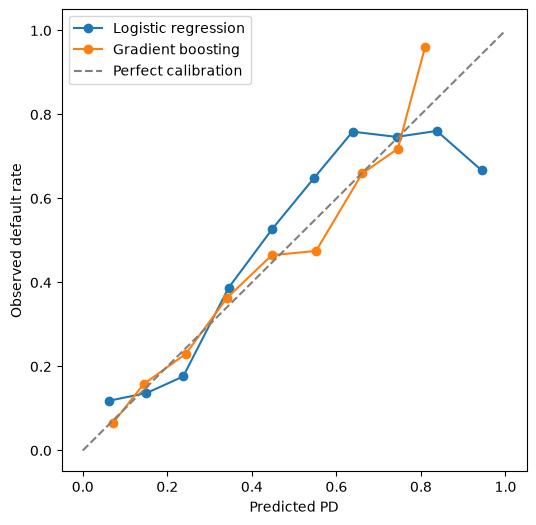

In [6]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Compare average predicted PD with the observed default rate
print("Observed default rate:", round(y_test.mean(), 3))
print("Mean PD logistic regression:", round(pd_test.mean(), 3))
print("Mean PD gradient boosting:", round(pd_test_gb.mean(), 3))

# Brier score: lower is better
print("Brier logistic regression:", round(brier_score_loss(y_test, pd_test), 4))
print("Brier gradient boosting:", round(brier_score_loss(y_test, pd_test_gb), 4))

# Calibration curve with 10 bins
fig, ax = plt.subplots(figsize=(6, 6))
for name, scores in [("Logistic regression", pd_test), ("Gradient boosting", pd_test_gb)]:
    frac_pos, mean_pred = calibration_curve(y_test, scores, n_bins=10)
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")
ax.set_xlabel("Predicted PD")
ax.set_ylabel("Observed default rate")
ax.legend()
plt.show()

In [8]:
import shap

# Explain the predicted probability of default (PD) on a sample of the test set
X_sample = X_test.sample(2000, random_state=42)
explainer = shap.Explainer(lambda data: gb.predict_proba(data)[:, 1], X_sample)
shap_values = explainer(X_sample)

# Global feature importance
shap.plots.bar(shap_values)

PermutationExplainer explainer:  12%|█▏        | 231/2000 [00:58<07:29,  3.93it/s]


KeyboardInterrupt: 

In [9]:
# Build a portfolio table from the test set
portfolio = X_test.copy()
portfolio["PD"] = pd_test_gb
portfolio["DEFAULT"] = y_test.values

# Simplified IFRS 9 staging rules (assumptions)
# Stage 3: 3+ months past due (90 days past due backstop)
# Stage 2: 1-2 months past due (30 days past due backstop) OR PD above the SICR threshold
# Stage 1: everything else
SICR_PD_THRESHOLD = 0.50

portfolio["STAGE"] = 1
portfolio.loc[
    (portfolio["PAY_1"] >= 1) | (portfolio["PD"] >= SICR_PD_THRESHOLD), "STAGE"
] = 2
portfolio.loc[portfolio["PAY_1"] >= 3, "STAGE"] = 3

print(portfolio["STAGE"].value_counts().sort_index())
print(portfolio.groupby("STAGE")[["PD", "DEFAULT"]].mean().round(3))

STAGE
1    6972
2    1873
3     155
Name: count, dtype: int64
          PD  DEFAULT
STAGE                
1      0.138    0.141
2      0.485    0.480
3      0.708    0.723


In [10]:
# Simplified ECL = PD x LGD x EAD (all assumptions documented in the README)
LGD = 0.75

# Exposure at default: latest bill amount, negative balances treated as zero
portfolio["EAD"] = portfolio["BILL_AMT1"].clip(lower=0)

# Stage 3 clients are already impaired, so PD is set to 1
portfolio["PD_ECL"] = portfolio["PD"]
portfolio.loc[portfolio["STAGE"] == 3, "PD_ECL"] = 1.0

portfolio["ECL"] = portfolio["PD_ECL"] * LGD * portfolio["EAD"]

summary = portfolio.groupby("STAGE").agg(
    clients=("ECL", "size"),
    total_EAD=("EAD", "sum"),
    total_ECL=("ECL", "sum"),
)
summary["coverage_ratio"] = summary["total_ECL"] / summary["total_EAD"]

print(summary.round(3))
print("Total ECL / Total EAD:", round(portfolio["ECL"].sum() / portfolio["EAD"].sum(), 3))

       clients  total_EAD     total_ECL  coverage_ratio
STAGE                                                  
1         6972  370086949  3.122078e+07           0.084
2         1873   83930143  3.546003e+07           0.422
3          155    7717684  5.788263e+06           0.750
Total ECL / Total EAD: 0.157


In [11]:
import numpy as np

def psi(expected, actual, bins=10):
    """Population Stability Index between a reference sample and a new sample."""
    # Bin edges come from the reference distribution (quantiles)
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf

    exp_pct = np.histogram(expected, bins=edges)[0] / len(expected)
    act_pct = np.histogram(actual, bins=edges)[0] / len(actual)

    # Avoid division by zero and log(0)
    exp_pct = np.clip(exp_pct, 1e-6, None)
    act_pct = np.clip(act_pct, 1e-6, None)

    return np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct))

# PSI of the model score (train vs test)
pd_train = gb.predict_proba(X_train)[:, 1]
print("PSI of PD score (train vs test):", round(psi(pd_train, pd_test_gb), 4))

# PSI of each input feature (train vs test), top 10
psi_features = pd.Series(
    {col: psi(X_train[col], X_test[col]) for col in X_train.columns}
).sort_values(ascending=False)
print(psi_features.round(4).head(10))

PSI of PD score (train vs test): 0.0014
PAY_AMT4     0.0021
PAY_AMT1     0.0015
BILL_AMT3    0.0013
BILL_AMT4    0.0011
PAY_AMT3     0.0011
BILL_AMT2    0.0008
LIMIT_BAL    0.0008
BILL_AMT5    0.0008
BILL_AMT6    0.0007
AGE          0.0007
dtype: float64


In [12]:
# Synthetic deterioration scenario (a stress test, not real drift)
X_stress = X_test.copy()
rng = np.random.default_rng(42)
hit = rng.random(len(X_stress)) < 0.20
X_stress.loc[hit, "PAY_1"] = (X_stress.loc[hit, "PAY_1"] + 1).clip(upper=8)

pd_stress = gb.predict_proba(X_stress)[:, 1]

print("Mean PD baseline:", round(pd_test_gb.mean(), 3))
print("Mean PD stressed:", round(pd_stress.mean(), 3))
print("PSI of PD score:", round(psi(pd_test_gb, pd_stress), 4))
print("PSI of PAY_1:", round(psi(X_test["PAY_1"], X_stress["PAY_1"]), 4))

Mean PD baseline: 0.22
Mean PD stressed: 0.233
PSI of PD score: 0.0141
PSI of PAY_1: 0.0609


In [13]:
# Compare several deterioration scenarios (share of clients hit, months added to PAY_1)
scenarios = [(0.20, 1), (0.40, 1), (0.40, 2), (0.60, 2)]
rows = []

for share, shift in scenarios:
    X_s = X_test.copy()
    rng = np.random.default_rng(42)
    hit = rng.random(len(X_s)) < share
    X_s.loc[hit, "PAY_1"] = (X_s.loc[hit, "PAY_1"] + shift).clip(upper=8)
    pd_s = gb.predict_proba(X_s)[:, 1]
    rows.append({
        "share_hit": share,
        "months_added": shift,
        "mean_PD": pd_s.mean(),
        "PSI_score": psi(pd_test_gb, pd_s),
        "PSI_PAY_1": psi(X_test["PAY_1"], X_s["PAY_1"]),
    })

print(pd.DataFrame(rows).round(4))

   share_hit  months_added  mean_PD  PSI_score  PSI_PAY_1
0        0.2             1   0.2331     0.0141     0.0609
1        0.4             1   0.2452     0.0526     0.2095
2        0.4             2   0.3359     0.2799     0.4364
3        0.6             2   0.3925     0.5658     0.8979
